In [1]:
!pip install hdbscan

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import hdbscan

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

In [3]:
iris = load_iris()

# Feature data
X = iris.data

# Original labels
y_true = iris.target

# Feature names
feature_names = iris.feature_names

# Original class names
target_names = iris.target_names

# Create DataFrame
df = pd.DataFrame(X, columns=feature_names)
df['Original_Label'] = y_true

display(df.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Original_Label
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [4]:
print("Dataset Information")
print("===================")

print("Total Samples :", X.shape[0])
print("Total Features:", X.shape[1])
print("Original Classes:", len(np.unique(y_true)))

print("\nFeature Names:")
print(feature_names)

print("\nOriginal Class Distribution:")
print(df['Original_Label'].value_counts().sort_index())

Dataset Information
Total Samples : 150
Total Features: 4
Original Classes: 3

Feature Names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Original Class Distribution:
Original_Label
0    50
1    50
2    50
Name: count, dtype: int64


In [5]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Data shape:", X_scaled.shape)

Data shape: (150, 4)


In [6]:
hdb = hdbscan.HDBSCAN(
    min_cluster_size=5,
    min_samples=5,
    metric='euclidean'
)

# Fit model
labels = hdb.fit_predict(X_scaled)

In [7]:
print("HDBSCAN Clustering Completed!")
print("Cluster Labels:", np.unique(labels))

HDBSCAN Clustering Completed!
Cluster Labels: [-1  0  1]


In [8]:
# Count clusters excluding noise (-1)
unique_clusters = set(labels)
n_clusters = len(unique_clusters - {-1})

# Count noise
n_noise = np.sum(labels == -1)

# Calculate noise percentage
noise_percentage = (n_noise / len(labels)) * 100

print("===== HDBSCAN RESULTS =====")
print("Number of Clusters :", n_clusters)
print("Amount of Noise    :", n_noise)
print(f"Noise Percentage   : {noise_percentage:.2f}%")

===== HDBSCAN RESULTS =====
Number of Clusters : 2
Amount of Noise    : 2
Noise Percentage   : 1.33%


In [9]:
cluster_distribution = pd.Series(labels).value_counts().sort_index()

print("Cluster Distribution:")
display(cluster_distribution)

Cluster Distribution:


,count
-1,2
0,99
1,49


In [10]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original Dimensions:", X_scaled.shape[1])
print("Reduced Dimensions :", X_pca.shape[1])

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print(
    "\nTotal Explained Variance:",
    f"{sum(pca.explained_variance_ratio_) * 100:.2f}%"
)

Original Dimensions: 4
Reduced Dimensions : 2

Explained Variance Ratio:
[0.72962445 0.22850762]

Total Explained Variance: 95.81%


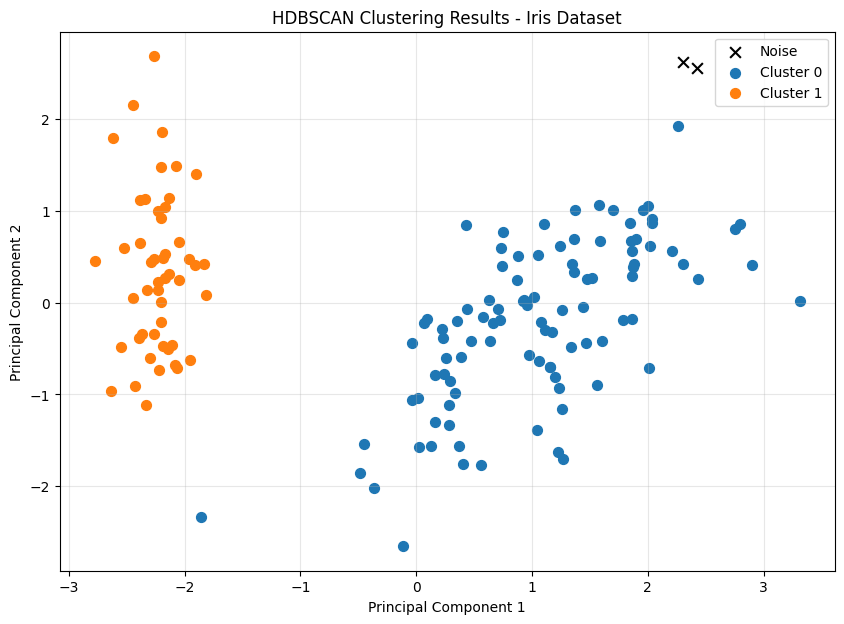

In [11]:
plt.figure(figsize=(10, 7))

# Plot each cluster
for cluster in sorted(set(labels)):
    mask = labels == cluster

    if cluster == -1:
        plt.scatter(
            X_pca[mask, 0],
            X_pca[mask, 1],
            color='black',
            marker='x',
            s=60,
            label='Noise'
        )
    else:
        plt.scatter(
            X_pca[mask, 0],
            X_pca[mask, 1],
            s=50,
            label=f'Cluster {cluster}'
        )

plt.title('HDBSCAN Clustering Results - Iris Dataset')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

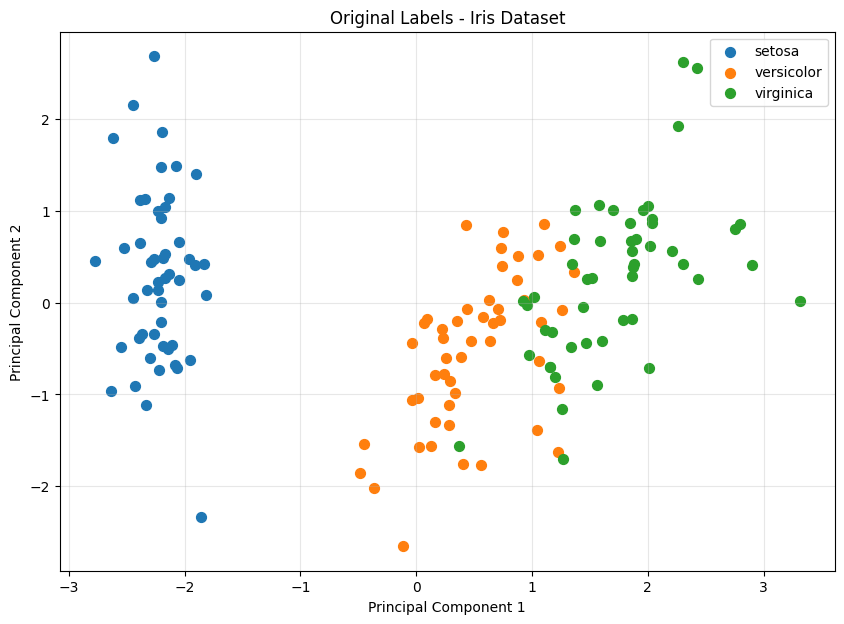

In [12]:
plt.figure(figsize=(10, 7))

for class_id, class_name in enumerate(target_names):
    mask = y_true == class_id

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        s=50,
        label=class_name
    )

plt.title('Original Labels - Iris Dataset')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [13]:
ari_score = adjusted_rand_score(y_true, labels)

print(f"Adjusted Rand Index: {ari_score:.4f}")

Adjusted Rand Index: 0.5394


In [14]:
comparison = pd.crosstab(
    pd.Series(y_true, name='Original Label'),
    pd.Series(labels, name='HDBSCAN Cluster')
)

display(comparison)

HDBSCAN Cluster,-1,0,1
Original Label,,,
0,0,1,49
1,0,50,0
2,2,48,0


In [15]:
print("===================================")
print("       HDBSCAN LAB ASSIGNMENT")
print("===================================")

print("\nDataset       : Iris Dataset")
print("Total Samples :", len(X))
print("Total Features:", X.shape[1])

print("\n--- Clustering Results ---")
print("Number of Clusters:", n_clusters)
print("Amount of Noise   :", n_noise)
print(f"Noise Percentage  : {noise_percentage:.2f}%")

print("\n--- Evaluation ---")
print(f"Adjusted Rand Index: {ari_score:.4f}")

print("\n--- Cluster Distribution ---")
print(cluster_distribution)

       HDBSCAN LAB ASSIGNMENT

Dataset       : Iris Dataset
Total Samples : 150
Total Features: 4

--- Clustering Results ---
Number of Clusters: 2
Amount of Noise   : 2
Noise Percentage  : 1.33%

--- Evaluation ---
Adjusted Rand Index: 0.5394

--- Cluster Distribution ---
-1     2
 0    99
 1    49
Name: count, dtype: int64
